In [26]:
import pandas as pd
import pypsa
import matplotlib.pyplot as plt
import numpy as np

In [21]:
# Same 4 bus network. Electricity demand will vary over 24 hours.
# Our first objective is to produce two simulated LMP time series: one with normal dispatch and one with N−1 security constraints.

n = pypsa.Network()

# 1. Add buses
for bus in ["A", "B", "C", "D"]:
    n.add("Bus", bus, v_nom=1.0)

# 2. Add transmission lines
line_data = [
    ("AB", "A", "B", 10),
    ("BC", "B", "C", 9),
    ("CD", "C", "D", 11),
    ("AD", "A", "D", 10),
    ("BD", "B", "D", 6),
]

for name, bus0, bus1, capacity in line_data:
    n.add(
        "Line",
        name,
        bus0=bus0,
        bus1=bus1,
        x=1.0,
        r=0.0,
        s_nom=capacity
    )

# 3. Add generators
generator_data = [
    ("G1", "A", 10, 20),
    ("G2", "A", 8, 35),
    ("G3", "B", 12, 65),
    ("G4", "D", 16, 90),
]

for name, bus, capacity, cost in generator_data:
    n.add(
        "Generator",
        name,
        bus=bus,
        p_nom=capacity,
        marginal_cost=cost
    )

# 4. Add loads
#n.add("Load", "Load_C", bus="C", p_set=4.99)
#n.add("Load", "Load_D", bus="D", p_set=11)


In [22]:
n_24 = n.copy()

# Create 24 hourly snapshots
hours = pd.date_range(
    "2026-10-26",
    periods=24,
    freq="h"
)

n_24.set_snapshots(hours)

# Register the loads as network components
n_24.add("Load", "Load_C", bus="C")
n_24.add("Load", "Load_D", bus="D")



In [23]:

load_c = [
    3, 3, 3, 3, 3, 3,
    4, 4, 5, 5, 6, 7,
    7, 7, 7, 7, 6, 6,
    5, 5, 4, 4, 3, 3
]

load_d = [
    8, 7, 7, 7, 7, 8,
    9, 10, 11, 11, 11, 11,
    11, 11, 12, 12, 13, 15,
    16, 15, 13, 11, 10, 9
]


n_24.loads_t.p_set = pd.DataFrame(
    {
        "Load_C": load_c,
        "Load_D": load_d
    },
    index=hours
)

print(n_24.loads_t.p_set.head())




                     Load_C  Load_D
2026-10-26 00:00:00       3       8
2026-10-26 01:00:00       3       7
2026-10-26 02:00:00       3       7
2026-10-26 03:00:00       3       7
2026-10-26 04:00:00       3       7


In [24]:

# Start from the unsolved 24-hour network
wind_24 = n_24.copy()

# Synthetic hourly wind capacity factors
wind_cf = [
    .70, .80, .75, .70, .65, .55,
    .45, .40, .30, .25, .20, .25,
    .30, .35, .50, .65, .75, .80,
    .90, .95, .85, .80, .75, .70
]

wind_24.add(
    "Generator",
    "Wind_C",
    bus="C",
    p_nom=6,
    marginal_cost=0,
    p_max_pu=pd.Series(wind_cf, index=wind_24.snapshots)
)

# Solve with the same N-1 security requirements
status, condition = wind_24.optimize.optimize_security_constrained(
    branch_outages=["BD", "BC"],
    solver_name="highs"
)

print(status, condition)




# Ordinary economic dispatch
normal_24 = n_24.copy()

normal_24.optimize(
    solver_name="highs"
)

# Security-constrained economic dispatch
secure_24 = n_24.copy()

secure_24.optimize.optimize_security_constrained(
    branch_outages=["BD", "BC"],
    solver_name="highs"
)


Index(['A', 'B', 'C', 'D'], dtype='object', name='name')
Index(['AB', 'BC', 'CD', 'AD', 'BD'], dtype='object', name='name')
Index(['AB', 'BC', 'CD', 'AD', 'BD'], dtype='object', name='name')
/Users/davidreynolds/.local/share/uv/python/cpython-3.14.7-macos-aarch64-none/lib/python3.14/contextlib.py:85: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  return func(*args, **kwds)
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.15s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 240 primals, 1104 duals
Objective: 7.41e+03
Solver: highs
Runtime: 0.01s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The sha

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-vj3g622m has 1104 rows; 240 cols; 1752 nonzeros
Coefficient ranges:
  Matrix  [3e-01, 1e+05]
  Cost    [2e+01, 9e+01]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 2e+01]
Presolving model
510 rows, 240 cols, 1236 nonzeros 0s
336 rows, 240 cols, 888 nonzeros 0s
Dependent equations search running on 144 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
336 rows, 240 cols, 888 nonzeros 0s
Presolve reductions: rows 336(-768); columns 240(-0); nonzeros 888(-864) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -1.0690840414e-02 Pr: 252(131854) 0.0s
        156     7.4075000000e+03 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.01s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 216 primals, 576 duals
Objective: 1.02e+04
Solver: highs
Runtime: 0.00s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Line-fix-s-lower, Line-fix-s-upper, Kirchhoff-Voltage-Law were not assigned to the network.
Index(['A', 'B', 'C', 'D'], dtype='object', name='name')
Index(['AB', 'BC', 'CD', 'AD', 'BD'], dtype='object', name='name')
Index(['AB', 'BC', 'CD', 'AD', 'BD'], dtype='object', name='name')
/Users/davidreynolds/.local/share/uv/python/cpython-3.14.7-macos-aarch64-none/lib/python3.14/contextlib.py:85: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` e

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-wb7f683t has 576 rows; 216 cols; 912 nonzeros
Coefficient ranges:
  Matrix  [1e+00, 1e+05]
  Cost    [2e+01, 9e+01]
  Bound   [0e+00, 0e+00]
  RHS     [3e+00, 2e+01]
Presolving model
96 rows, 168 cols, 312 nonzeros 0s
Dependent equations search running on 96 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
96 rows, 168 cols, 312 nonzeros 0s
Presolve reductions: rows 96(-480); columns 168(-48); nonzeros 312(-600) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -5.9287572804e-03 Pr: 96(49079.2) 0.0s
        104     1.0170000000e+04 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-p

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.02s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 216 primals, 1056 duals
Objective: 1.17e+04
Solver: highs
Runtime: 0.00s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Line-fix-s-lower, Line-fix-s-upper, Kirchhoff-Voltage-Law, Line-fix-s-lower-security-for-Line-outage-in-sub-network-0, Line-fix-s-upper-security-for-Line-outage-in-sub-network-0 were not assigned to the network.


Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-2_d_eoue has 1056 rows; 216 cols; 1680 nonzeros
Coefficient ranges:
  Matrix  [3e-01, 1e+05]
  Cost    [2e+01, 9e+01]
  Bound   [0e+00, 0e+00]
  RHS     [3e+00, 2e+01]
Presolving model
272 rows, 168 cols, 664 nonzeros 0s
196 rows, 139 cols, 491 nonzeros 0s
133 rows, 136 cols, 362 nonzeros 0s
Dependent equations search running on 64 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
133 rows, 136 cols, 362 nonzeros 0s
Presolve reductions: rows 133(-923); columns 136(-80); nonzeros 362(-1318) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -1.9438697368e-03 Pr: 109(24620) 0.0s
         84     1.1736666667e+04 Pr: 0(0) 0.0s

Performed postsolve
Solving the 

('ok', 'optimal')

In [14]:
print(secure_24.generators_t.p.round(2))

print(secure_24.buses_t.marginal_price.round(2))

name                   G1    G2   G3    G4
snapshot                                  
2026-10-26 00:00:00  10.0  1.00 -0.0 -0.00
2026-10-26 01:00:00  10.0 -0.00 -0.0 -0.00
2026-10-26 02:00:00  10.0 -0.00 -0.0 -0.00
2026-10-26 03:00:00  10.0 -0.00 -0.0 -0.00
2026-10-26 04:00:00  10.0 -0.00 -0.0 -0.00
2026-10-26 05:00:00  10.0  1.00 -0.0 -0.00
2026-10-26 06:00:00  10.0  3.00 -0.0 -0.00
2026-10-26 07:00:00  10.0  4.00 -0.0 -0.00
2026-10-26 08:00:00  10.0  5.00 -0.0  1.00
2026-10-26 09:00:00  10.0  5.00 -0.0  1.00
2026-10-26 10:00:00  10.0  5.00 -0.0  2.00
2026-10-26 11:00:00  10.0  5.00 -0.0  3.00
2026-10-26 12:00:00  10.0  5.00 -0.0  3.00
2026-10-26 13:00:00  10.0  5.00 -0.0  3.00
2026-10-26 14:00:00  10.0  5.00 -0.0  4.00
2026-10-26 15:00:00  10.0  5.00 -0.0  4.00
2026-10-26 16:00:00  10.0  5.00 -0.0  4.00
2026-10-26 17:00:00  10.0  5.00 -0.0  6.00
2026-10-26 18:00:00  10.0  5.00 -0.0  6.00
2026-10-26 19:00:00  10.0  5.00 -0.0  5.00
2026-10-26 20:00:00  10.0  4.67 -0.0  2.33
2026-10-26 

In [15]:

# Calculate generation cost in each hour
cost_normal = (
    normal_24.generators_t.p
    * normal_24.generators.marginal_cost
).sum(axis=1)

cost_secure = (
    secure_24.generators_t.p
    * secure_24.generators.marginal_cost
).sum(axis=1)

comparison = pd.DataFrame({
    "Load": n_24.loads_t.p_set.sum(axis=1),
    "Cost_Normal": cost_normal,
    "Cost_Secure": cost_secure
})

comparison["Security_Premium"] = (
    comparison["Cost_Secure"]
    - comparison["Cost_Normal"]
)

print(comparison.round(2))


                     Load  Cost_Normal  Cost_Secure  Security_Premium
2026-10-26 00:00:00    11        235.0       235.00              0.00
2026-10-26 01:00:00    10        200.0       200.00              0.00
2026-10-26 02:00:00    10        200.0       200.00              0.00
2026-10-26 03:00:00    10        200.0       200.00              0.00
2026-10-26 04:00:00    10        200.0       200.00              0.00
2026-10-26 05:00:00    11        235.0       235.00              0.00
2026-10-26 06:00:00    13        305.0       305.00              0.00
2026-10-26 07:00:00    14        340.0       340.00              0.00
2026-10-26 08:00:00    16        410.0       465.00             55.00
2026-10-26 09:00:00    16        410.0       465.00             55.00
2026-10-26 10:00:00    17        445.0       555.00            110.00
2026-10-26 11:00:00    18        510.0       645.00            135.00
2026-10-26 12:00:00    18        510.0       645.00            135.00
2026-10-26 13:00:00 

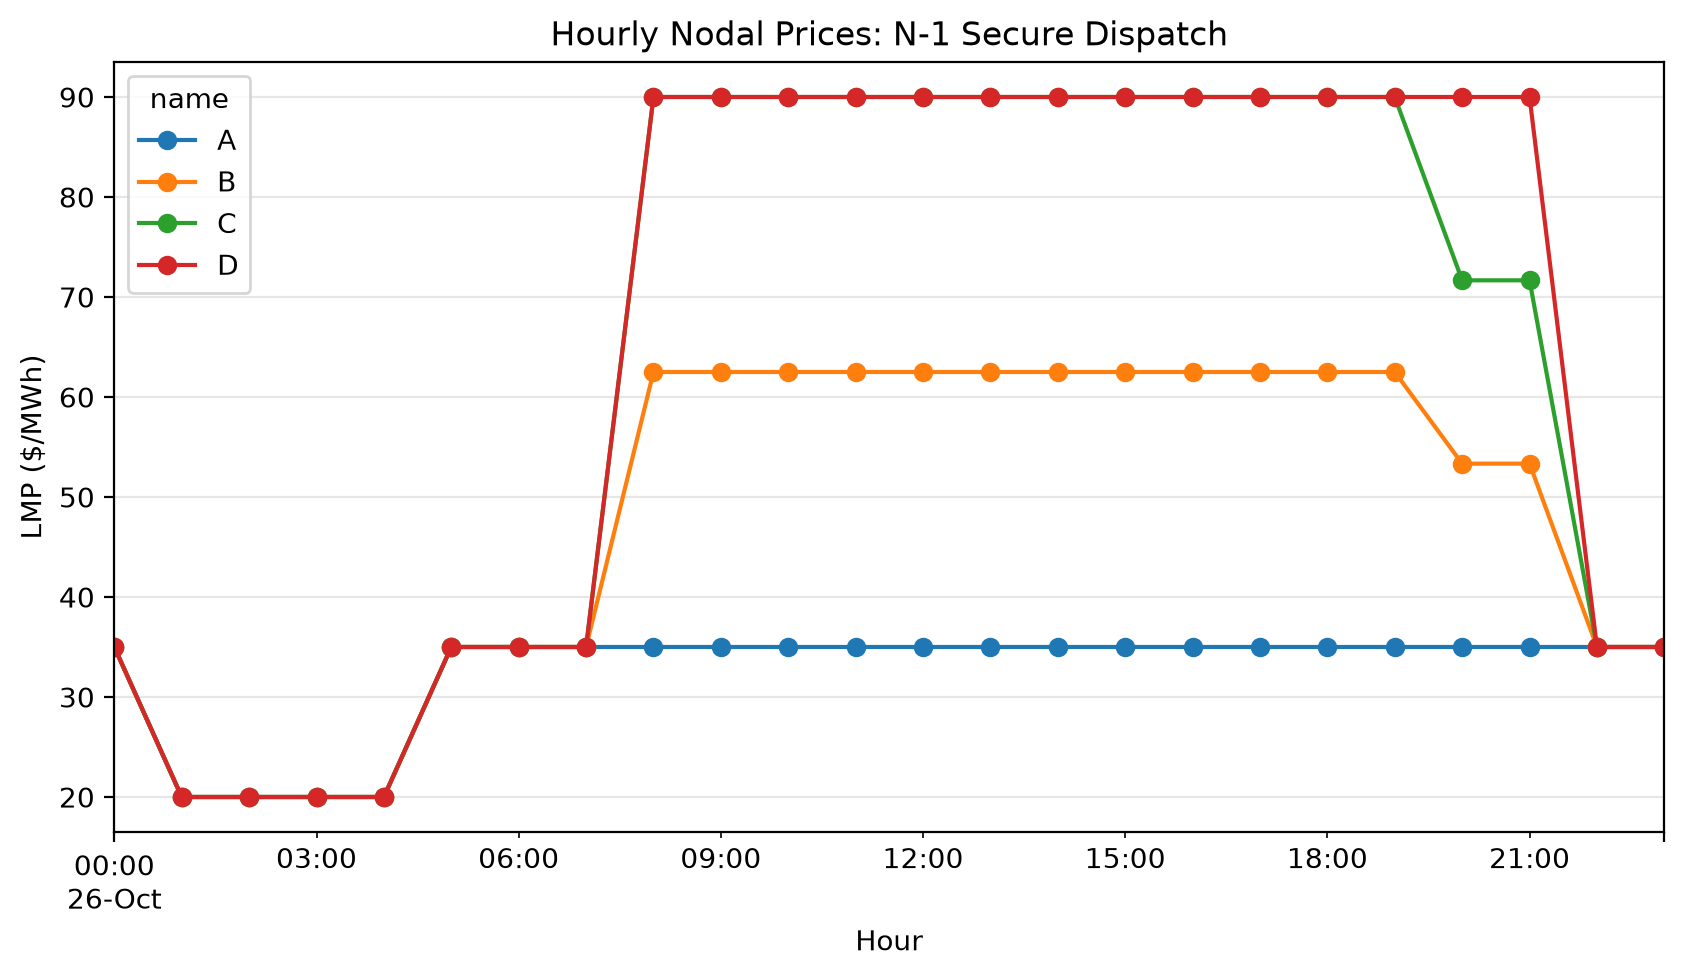

In [16]:

secure_24.buses_t.marginal_price.plot(
    figsize=(10, 5),
    marker="o"
)

plt.title("Hourly Nodal Prices: N-1 Secure Dispatch")
plt.xlabel("Hour")
plt.ylabel("LMP ($/MWh)")
plt.grid(alpha=0.3)
plt.show()


In [17]:
print("Defined loads:")
print(n_24.loads[["bus", "p_set"]])

print("\nHourly loads:")
print(n_24.loads_t.p_set.iloc[[0, 8, 18]])

print("\nTotal load at 8 AM:")
print(n_24.loads_t.p_set.iloc[8].sum())

Defined loads:
       bus  p_set
name             
Load_C   C    0.0
Load_D   D    0.0

Hourly loads:
                     Load_C  Load_D
2026-10-26 00:00:00       3       8
2026-10-26 08:00:00       5      11
2026-10-26 18:00:00       5      16

Total load at 8 AM:
16


In [18]:

# Hourly generation costs
cost_normal = (
    normal_24.generators_t.p
    * normal_24.generators.marginal_cost
).sum(axis=1)

cost_secure = (
    secure_24.generators_t.p
    * secure_24.generators.marginal_cost
).sum(axis=1)

# Nodal prices
lmps = secure_24.buses_t.marginal_price

# Combined hourly results
summary = pd.DataFrame({
    "Load": n_24.loads_t.p_set.sum(axis=1),
    "G4_Output": secure_24.generators_t.p["G4"],
    "Normal_Cost": cost_normal,
    "Secure_Cost": cost_secure,
    "LMP_A": lmps["A"],
    "LMP_D": lmps["D"]
})

summary["Security_Premium"] = (
    summary["Secure_Cost"] - summary["Normal_Cost"]
)

summary["Price_Spread_DA"] = (
    summary["LMP_D"] - summary["LMP_A"]
)

print(summary.round(2).to_string())


                     Load  G4_Output  Normal_Cost  Secure_Cost  LMP_A  LMP_D  Security_Premium  Price_Spread_DA
2026-10-26 00:00:00    11      -0.00        235.0       235.00   35.0   35.0              0.00              0.0
2026-10-26 01:00:00    10      -0.00        200.0       200.00   20.0   20.0              0.00              0.0
2026-10-26 02:00:00    10      -0.00        200.0       200.00   20.0   20.0              0.00              0.0
2026-10-26 03:00:00    10      -0.00        200.0       200.00   20.0   20.0              0.00              0.0
2026-10-26 04:00:00    10      -0.00        200.0       200.00   20.0   20.0              0.00              0.0
2026-10-26 05:00:00    11      -0.00        235.0       235.00   35.0   35.0              0.00              0.0
2026-10-26 06:00:00    13      -0.00        305.0       305.00   35.0   35.0              0.00              0.0
2026-10-26 07:00:00    14      -0.00        340.0       340.00   35.0   35.0              0.00          

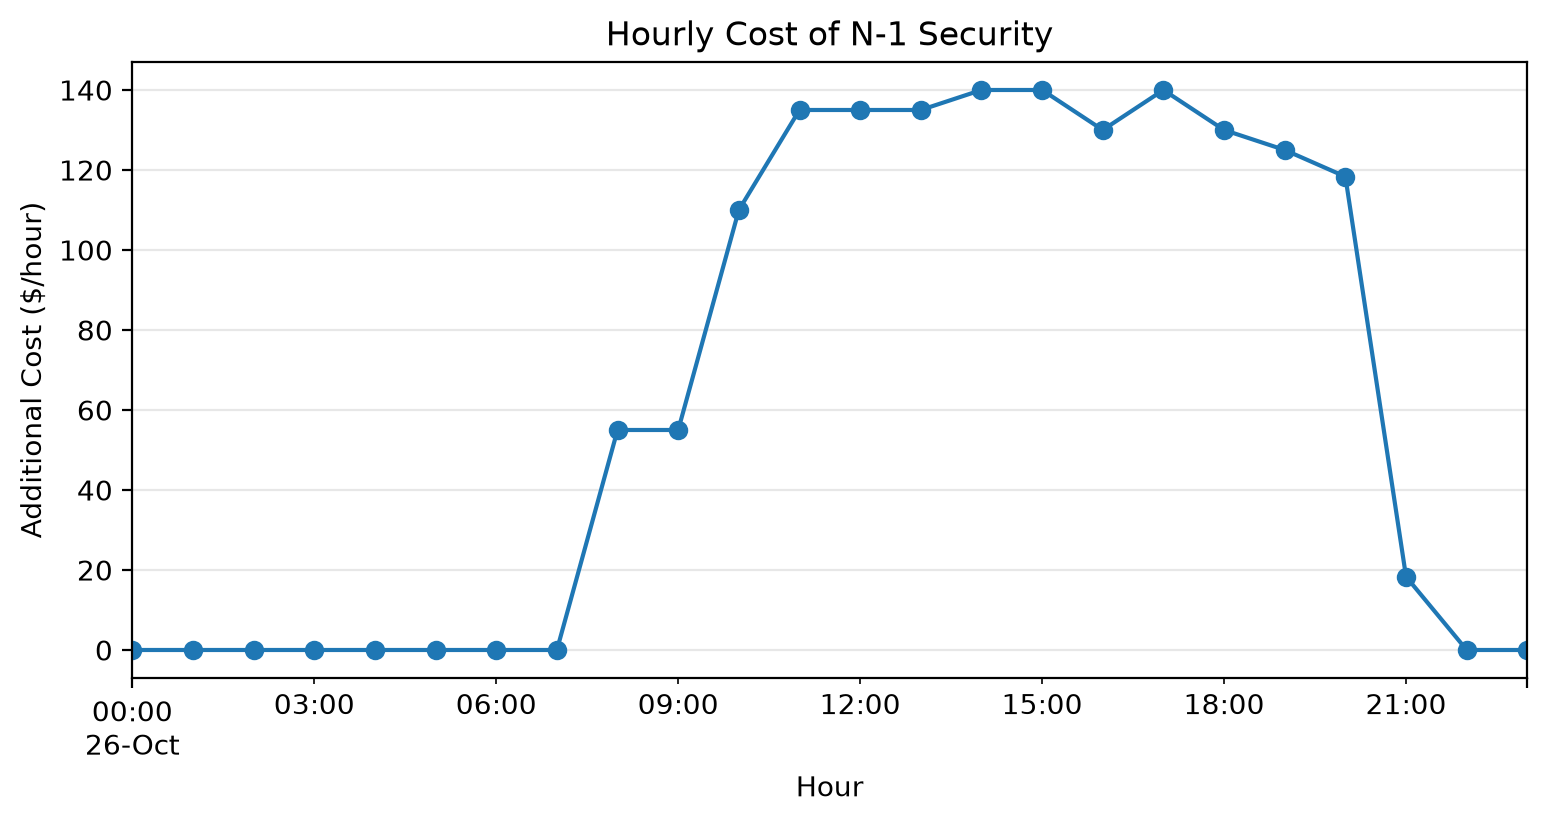

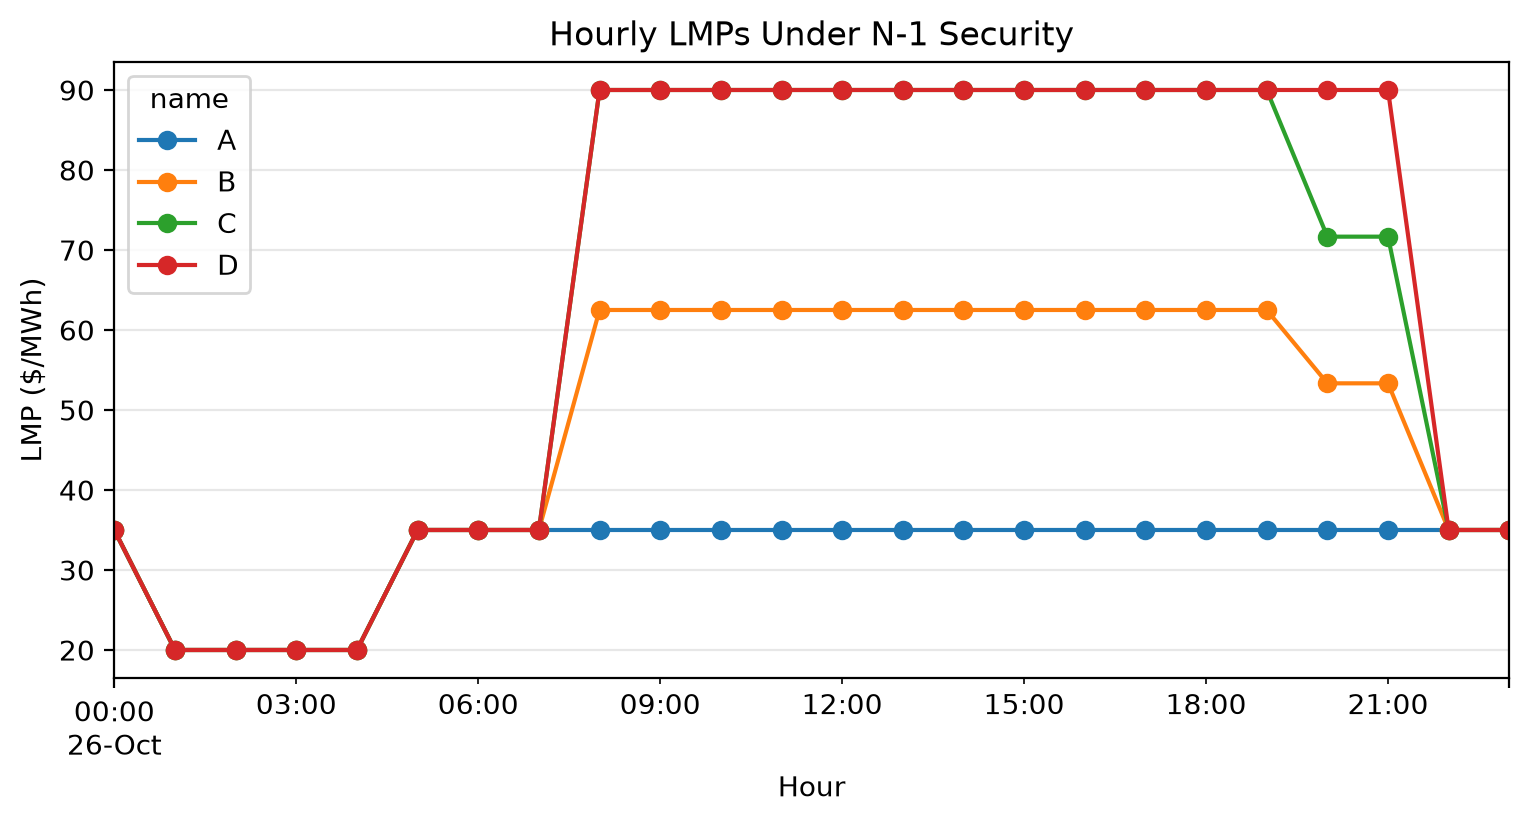

In [19]:

# Security premium throughout the day
summary["Security_Premium"].plot(
    figsize=(9, 4),
    marker="o",
    title="Hourly Cost of N-1 Security"
)
plt.ylabel("Additional Cost ($/hour)")
plt.xlabel("Hour")
plt.grid(alpha=0.3)
plt.show()

# Nodal prices throughout the day
lmps.plot(
    figsize=(9, 4),
    marker="o",
    title="Hourly LMPs Under N-1 Security"
)
plt.ylabel("LMP ($/MWh)")
plt.xlabel("Hour")
plt.grid(alpha=0.3)
plt.show()


In [27]:

comparison_wind = pd.DataFrame({
    "Wind_Available": 6 * np.array(wind_cf),
    "Wind_Produced": wind_24.generators_t.p["Wind_C"],
    "G4_Without_Wind": secure_24.generators_t.p["G4"],
    "G4_With_Wind": wind_24.generators_t.p["G4"],
    "Spread_Without_Wind": (
        secure_24.buses_t.marginal_price["D"]
        - secure_24.buses_t.marginal_price["A"]
    ),
    "Spread_With_Wind": (
        wind_24.buses_t.marginal_price["D"]
        - wind_24.buses_t.marginal_price["A"]
    )
})

print(comparison_wind.round(2))


                     Wind_Available  Wind_Produced  G4_Without_Wind  \
snapshot                                                              
2026-10-26 00:00:00             4.2            4.2            -0.00   
2026-10-26 01:00:00             4.8            4.8            -0.00   
2026-10-26 02:00:00             4.5            4.5            -0.00   
2026-10-26 03:00:00             4.2            4.2            -0.00   
2026-10-26 04:00:00             3.9            3.9            -0.00   
2026-10-26 05:00:00             3.3            3.3            -0.00   
2026-10-26 06:00:00             2.7            2.7            -0.00   
2026-10-26 07:00:00             2.4            2.4            -0.00   
2026-10-26 08:00:00             1.8            1.8             1.00   
2026-10-26 09:00:00             1.5            1.5             1.00   
2026-10-26 10:00:00             1.2            1.2             2.00   
2026-10-26 11:00:00             1.5            1.5             3.00   
2026-1